# 2. Clasificación con Validación Cruzada k-Fold

**Materia:** Aprendizaje Automático (Machine Learning)
**Trabajo Práctico 2:** Clasificación Supervisada
**Dataset:** Bank Marketing (UCI / Kaggle)  
**Objetivo:** Entrenar y comparar los cuatro algoritmos requeridos (**Gaussian Naive Bayes, SVM, KNN y Random Forest**) con **validación cruzada estratificada ($k=5$)** sobre el conjunto de entrenamiento.

---

### Metodología:
1. **Un subconjunto de variables por modelo** (definidos en el notebook 1): set 1 → Random Forest, set 2 → SVM y Naive Bayes, set 3 → KNN.
2. **Prevención de Data Leakage:** `StandardScaler` dentro de un `Pipeline`, ajustado solo con los folds de entrenamiento.
3. **Métricas:** **ROC-AUC** y **F1-score** de la clase minoritaria (`yes`).
4. **Diagnóstico de sobreajuste:** brecha de generalización (train − validación).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
DATA_PATH = Path("../data")
FIGURES_PATH = Path("../figures")

## Subconjunto de variables de cada modelo y preprocesamiento
- **Variables continuas:** `StandardScaler()` ajustado pliegue a pliegue.
- **Variables binarias (0/1):** `passthrough`.
- El test set no se utiliza en este cuaderno.

In [2]:
CLASSIFIER_DATASETS = {
    "Naive Bayes": "set2_core_decorrelated",
    "SVM": "set2_core_decorrelated",
    "KNN": "set3_minimalist_knn",
    "Random Forest": "set1_high_capacity",
}
BINARY_FEATURES = ["poutcome_success", "contact", "month_may", "month_mar", "month_oct"]


def load_train_set(set_name):
    train_data = pd.read_csv(DATA_PATH / f"ds_train_{set_name}.csv")
    return train_data.drop(columns="y"), train_data["y"]


def build_preprocessor(features):
    numerical_features = [feature for feature in features if feature not in BINARY_FEATURES]
    binary_features = [feature for feature in features if feature in BINARY_FEATURES]
    return ColumnTransformer([
        ("numerical", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features),
    ])

In [3]:
for classifier_name, set_name in CLASSIFIER_DATASETS.items():
    X_train, y_train = load_train_set(set_name)
    print(f"{classifier_name:<14} → {set_name:<24} {X_train.shape}  % yes = {y_train.mean():.2%}")

Naive Bayes    → set2_core_decorrelated   (32940, 7)  % yes = 11.27%
SVM            → set2_core_decorrelated   (32940, 7)  % yes = 11.27%
KNN            → set3_minimalist_knn      (32940, 5)  % yes = 11.27%
Random Forest  → set1_high_capacity       (32940, 14)  % yes = 11.27%


## Clasificadores (hiperparámetros por defecto)
`class_weight="balanced"` en SVM y Random Forest para compensar el desbalance de clases (11% yes).

In [4]:
classifiers = {
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(class_weight="balanced", random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}

## Elección y Justificación de Métricas
- **ROC-AUC:** Evalúa la capacidad de ordenar a los clientes para cualquier umbral; no se ve afectada por el desbalance de clases.
- **F1 (clase 'yes'):** Media armónica entre precisión y recall de la clase minoritaria; accuracy es engañosa (88.7% prediciendo siempre 'no').

In [5]:
SCORING_METRICS = ["roc_auc", "f1"]

## Validación cruzada estratificada (5 folds · Conjunto de Train)
Los tres subconjuntos tienen las mismas filas en el mismo orden, por lo que los 5 folds son idénticos para los 4 modelos.

In [6]:
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = []
for classifier_name, classifier in classifiers.items():
    X_train, y_train = load_train_set(CLASSIFIER_DATASETS[classifier_name])
    classification_pipeline = Pipeline([
        ("preprocessing", build_preprocessor(X_train.columns)),
        ("classifier", classifier),
    ])
    fold_scores = cross_validate(
        classification_pipeline, X_train, y_train,
        cv=stratified_kfold,
        scoring=SCORING_METRICS,
        return_train_score=True,
        n_jobs=-1,
    )
    for metric in SCORING_METRICS:
        cv_results.append({
            "classifier": classifier_name,
            "metric": metric,
            "train_mean": fold_scores[f"train_{metric}"].mean(),
            "validation_mean": fold_scores[f"test_{metric}"].mean(),
            "validation_std": fold_scores[f"test_{metric}"].std(),
        })
    print(f"{classifier_name}: completado")

Naive Bayes: completado


SVM: completado


KNN: completado


Random Forest: completado


## Resultados de validación cruzada

In [7]:
cv_results = pd.DataFrame(cv_results)
cv_results.round(3)

,classifier,metric,train_mean,validation_mean,validation_std
0,Naive Bayes,roc_auc,0.752,0.752,0.010
1,Naive Bayes,f1,0.343,0.343,0.012
2,SVM,roc_auc,0.771,0.764,0.010
3,SVM,f1,0.443,0.438,0.022
4,KNN,roc_auc,0.827,0.714,0.007
5,KNN,f1,0.465,0.340,0.010
6,Random Forest,roc_auc,0.957,0.725,0.013
7,Random Forest,f1,0.581,0.341,0.012


## Comparación de clasificadores (Media ± Desvío en los 5 folds de validación)

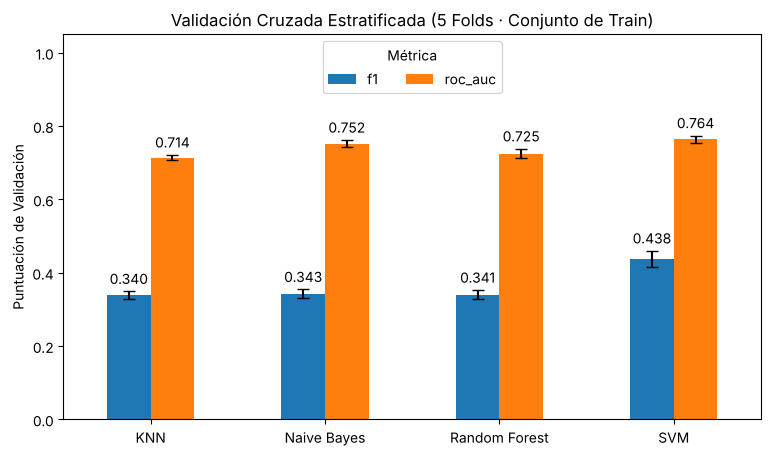

In [8]:
validation_means = cv_results.pivot(index="classifier", columns="metric", values="validation_mean")
validation_stds = cv_results.pivot(index="classifier", columns="metric", values="validation_std")

ax = validation_means.plot(kind="bar", yerr=validation_stds, capsize=4, figsize=(9, 5), rot=0)
for bars in ax.containers:
    if hasattr(bars, "patches"):
        ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, 1.05)
ax.legend(title="Métrica", loc="upper center", ncols=2)
ax.set_xlabel("")
ax.set_ylabel("Puntuación de Validación")
ax.set_title("Validación Cruzada Estratificada (5 Folds · Conjunto de Train)")
plt.savefig(FIGURES_PATH / "07_cv_classifier_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

## Brecha de generalización (Train − Validación)
Diagnóstico de sobreajuste: discrepancias grandes entre el desempeño en entrenamiento y validación evidencian memorización de ruido.

In [9]:
cv_results["generalization_gap"] = cv_results["train_mean"] - cv_results["validation_mean"]
cv_results.pivot(index="classifier", columns="metric", values="generalization_gap").round(3)

metric,f1,roc_auc
classifier,,
KNN,0.126,0.113
Naive Bayes,0.000,0.000
Random Forest,0.240,0.232
SVM,0.005,0.008


## Conclusiones del Paso 2
- **SVM** (set 2) obtiene el mejor desempeño con hiperparámetros por defecto (ROC-AUC 0.764, F1 0.438) y casi no tiene brecha.
- **Random Forest** (0.957 train vs. 0.725 validación) y **KNN** (0.827 vs. 0.714) sobreajustan con sus valores por defecto (árboles sin límite de profundidad; k = 5).
- **Naive Bayes** no sobreajusta (brecha 0.000) pero tiene alto sesgo (ROC-AUC 0.752).
- En el **Paso 3** se ajustan los hiperparámetros con curvas de validación.